In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [2]:
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
import matplotlib
from sklearn.manifold import TSNE
import torch
from Experiment_10.net import Net
import torch
from Experiment_10.ParametricWMTask import generate_trials
from sklearn.decomposition import PCA
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
u, z, mask, conditions = generate_trials(n_trials=25)

In [ ]:
u.shape

In [23]:
rows = []


for gain_target in np.linspace(0,1,20):
    print(gain_target)
    u, z, mask, conditions = generate_trials(n_trials=25)

    net = Net(n=1000, input_size=u.shape[2],output_size=u.shape[2],
              dale=False,
              sigma_in=0.,
              sigma_rec = 0.,
              base_in=0.1,
              lambda_std=0.4,
              beta=
              20)
    # Fit 4
    dim = 4
    print("Fitting")
    net.fit(u,
            z,
            mask,
            lr=.005,
            epochs=100,
            conditions=conditions,
            verbose=True,
            dim=dim,
            weight_decay=0.001,
            pca_target_1 = .1,
            pca_target_2=0,
            gain_target=gain_target,
            kmeans_target = 0,
            lambda_gain_mean=1,
            lambda_gain_std=0,
            lambda_pca_1=.1,
            lambda_pca_2=1,
                                )

    net.sigma_rec = 0.1
    x = net(u)

    # Condition averages
    x = x.detach().cpu().numpy()
    # x = iterative_outlier_detection(x)
    response_rows = []
    for trial in range(x.shape[0]):
        response_rows.append({"trial": trial,
                     'theta': conditions[trial]['theta'].item(),
                     'y': x[trial, :, :],})
    response_df = pd.DataFrame(response_rows)
    new_df = response_df.groupby('theta').y.apply(lambda x: np.stack(x)).reset_index()
    response_matrix = np.stack(new_df.y.values) # (n_conditions x trials_per_condition x time x n_neurons)
    response_matrix = (response_matrix - np.mean(response_matrix, axis=(0, 1, 2), keepdims=True)) / np.std(
    response_matrix, axis=(0, 1, 2), keepdims=True)
    # Mean responses across trials per condition
    responses = np.mean(response_matrix, axis=1) # (n_conditions x time x neurons)
    responses = responses.reshape(-1, responses.shape[2]) # (n_conditions.time x neurons)

    # Within condition deviation
    snr = np.mean(np.std(response_matrix, axis=1), axis=(0, 1))
    snr_mean = np.mean(snr)

    # Compute gain
    x = torch.tensor(x).float()
    h = net.recurrent_layer(x) + net.input_layer(u)
    h = h - torch.mean(h, dim=(0, 1), keepdim=True)

    z = x - torch.mean(x, dim=[0, 1], keepdim=True)
    gain = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))

    for neuron in range(x.shape[2]):
        rows.append({"neuron": neuron,
                     'gain_target': gain_target,
                     'snr': snr[neuron].item(),
                     'gain': gain[neuron].item(),})


0.0
Fitting
Epoch: 10/100............. task_loss: 1.0094 pca: 0.0898 pca_1: 0.1025 pca_2: 0.0898
Epoch: 20/100............. task_loss: 1.0367 pca: 0.0561 pca_1: 0.0934 pca_2: 0.0561
Epoch: 30/100............. task_loss: 1.0157 pca: 0.0425 pca_1: 0.0816 pca_2: 0.0425
Epoch: 40/100............. task_loss: 1.0295 pca: 0.0400 pca_1: 0.0819 pca_2: 0.0400
Epoch: 50/100............. task_loss: 1.0243 pca: 0.0368 pca_1: 0.0947 pca_2: 0.0368
Epoch: 60/100............. task_loss: 1.0100 pca: 0.0277 pca_1: 0.0941 pca_2: 0.0277
Epoch: 70/100............. task_loss: 1.0072 pca: 0.0175 pca_1: 0.1076 pca_2: 0.0175
Epoch: 80/100............. task_loss: 1.0961 pca: 0.0079 pca_1: 0.1158 pca_2: 0.0079
Epoch: 90/100............. task_loss: 1.0734 pca: 0.0045 pca_1: 0.1160 pca_2: 0.0045
Epoch: 100/100............. task_loss: 1.1231 pca: 0.0037 pca_1: 0.1011 pca_2: 0.0037
0.05263157894736842
Fitting


KeyboardInterrupt: 

In [49]:
df = pd.DataFrame(rows)
df

,neuron,gain_target,snr,gain
0,0,0.0,0.085445,0.710926
1,1,0.0,0.085858,0.655505
2,2,0.0,0.086826,0.774826
3,3,0.0,0.086719,0.671801
4,4,0.0,0.087072,0.484791
...,...,...,...,...
1995,95,1.0,0.086089,0.775150
1996,96,1.0,0.085223,0.754964
1997,97,1.0,0.083149,0.774707
1998,98,1.0,0.087401,0.675605


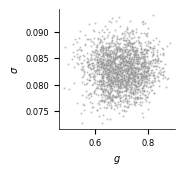

In [50]:
fig = plt.figure(figsize=(1.5,1.55))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.scatterplot(data =df ,x = 'gain',y = 'snr',ax= ax, color='gray',s = 2,alpha  =.5)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(True)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_eeeedrefswdei = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.set_xlabel(r"$g$",size = 7)
ax.set_ylabel(r"$\sigma$",size = 7)
plt.savefig('Figures/Figure_boundary_8.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [38]:
# Checking relationship in single
u, z, mask, conditions = generate_trials(n_trials=25)

net = Net(n=1000, input_size=u.shape[2],output_size=u.shape[2],
          dale=False,
          sigma_in=0.,
          sigma_rec = 0.1,
          base_in=0.1,
          lambda_std=0.4,
          beta=
          20)
# Fit 4
dim = 4
print("Fitting")
net.fit(u,
        z,
        mask,
        lr=.005,
        epochs=100,
        conditions=conditions,
        verbose=True,
        dim=dim,
        weight_decay=0.001,
        pca_target_1 = .1,
        pca_target_2=0,
        gain_target=1,
        kmeans_target = 0,
        lambda_gain_mean=0,
        lambda_gain_std=0,
        lambda_pca_1=.1,
        lambda_pca_2=1,
                            )

Fitting
Epoch: 10/100............. task_loss: 1.0330 pca: 0.1778 pca_1: 0.0908 pca_2: 0.1778


KeyboardInterrupt: 

In [42]:

x = net(u)

# Condition averages
x = x.detach()
h = net.recurrent_layer(x) + net.input_layer(u)
h = h - torch.mean(h, dim=(0, 1), keepdim=True)

z = x - torch.mean(x, dim=[0, 1], keepdim=True)
gain = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))
gain = torch.mean(x,dim = (0,1))
x = x.detach().cpu().numpy()
# x = iterative_outlier_detection(x)
response_rows = []
for trial in range(x.shape[0]):
    response_rows.append({"trial": trial,
                 'theta': conditions[trial]['theta'].item(),
                 'y': x[trial, :, :],})
response_df = pd.DataFrame(response_rows)
new_df = response_df.groupby('theta').y.apply(lambda x: np.stack(x)).reset_index()
response_matrix = np.stack(new_df.y.values) # (n_conditions x trials_per_condition x time x n_neurons)
response_matrix = (response_matrix - np.mean(response_matrix, axis=(0, 1, 2), keepdims=True)) / np.std(
response_matrix, axis=(0, 1, 2), keepdims=True)
# Mean responses across trials per condition
responses = np.mean(response_matrix, axis=1) # (n_conditions x time x neurons)
responses = responses.reshape(-1, responses.shape[2]) # (n_conditions.time x neurons)

# Within condition deviation
snr = np.mean(np.std(response_matrix, axis=1), axis=(0, 1))


(-0.619753897190094, 0.9120975136756897)

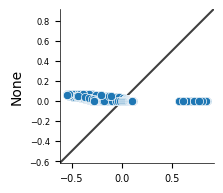

In [40]:
fig = plt.figure(figsize=(2, 2))

gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])
sns.scatterplot(x = h[:,:,2].detach().flatten(),y = z[:,:,2].detach().flatten(),ax=ax)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.set_xlabel('')
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
lims = [
    np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
    np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
]

# now plot both limits against eachother
ax.plot(lims, lims, 'k-', alpha=0.75, zorder=0)
ax.set_aspect('equal')
ax.set_xlim(lims)
ax.set_ylim(lims)


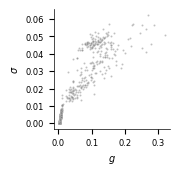

In [43]:
fig = plt.figure(figsize=(1.5,1.55))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.scatterplot(x =gain.detach().numpy(),y = snr,ax= ax, color='gray',s = 2,alpha  =.5)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(True)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_eeeedrefswdei = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.set_xlabel(r"$g$",size = 7)
ax.set_ylabel(r"$\sigma$",size = 7)
plt.savefig('Figures/Figure_boundary_8.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [8]:
response_matrix.shape

(50, 25, 75, 1000)

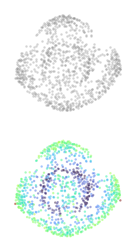

In [30]:
####################################################################
#################### CLUSTERING PLOT ###############################
####################################################################
import umap
net.sigma_rec = 0

x = net(u).detach()
h = net.recurrent_layer(x) + net.input_layer(u)
h = h - torch.mean(h, dim=(0, 1), keepdim=True)

z = x - torch.mean(x, dim=[0, 1], keepdim=True)
# dist = torch.var(z @ self.recurrent_layer.weight.t()) / torch.var(h, dim=(0, 1))

beta = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))

mag = torch.mean(x,dim = (0,1))

x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
#x = x  + 2*(2*torch.rand_like(x)-1)
x = x.numpy()
#x_proj  = PCA(n_components = 2).fit_transform(responses.T)
#x_proj  = TSNE(n_components = 2,perplexity = 800).fit_transform(x.reshape(-1,x.shape[2]).T)
x_proj  = TSNE(n_components = 2,perplexity = 200).fit_transform(responses.T)
# fit = umap.UMAP(densmap=True,dens_lambda =1)
# x_proj= fit.fit_transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(3,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=3,ax=ax0,color='gray',alpha = .35,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=3,hue =snr,alpha = .5,legend = False,palette = 'turbo')
for ax in [ax0,ax1]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_.jpg')
